# Slinger
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:** [eigen naam invullen]  
**Title of the experiment:** Nauwkeurige bepaling van $g$ met een slinger  
**Starting date:** [datum invullen]  
**Expected enddate:** [datum invullen]  
**Partner:** [naam partner invullen]  
**Goal of the experiment:** De lokale zwaartekrachtsversnelling $g$ bepalen met een slinger, met een foutmarge kleiner dan 0.5\% ten opzichte van de gebruikte waarde in Delft.  
**Research question:** Kan de zwaartekrachtsversnelling $g$ met een slinger binnen 0.5\% van de geaccepteerde waarde in Delft worden bepaald?  
**Expectations or Hypothesis:** We verwachten een waarde dichtbij $g = 9.812\,\mathrm{m\,s^{-2}}$. Door meerdere periodes tegelijk te meten verwachten we de relatieve tijdsonzekerheid kleiner te maken dan bij het meten van één periode.  
**Desired accuracy:** 0.5\%  


In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy.optimize import curve_fit 

## Preparation
 


**Assignments:**  

Voor de voorbereiding testen we thuis een slinger met een lengte van ongeveer $1.0\,\mathrm{m}$ met de stopwatch van een telefoon.

Eerst meten we vijf keer ongeveer één periode. Daarna meten we vijf keer de tijd van 10 periodes en delen deze tijd door 10. Van beide methodes bepalen we het gemiddelde, de standaarddeviatie en de onzekerheid van het gemiddelde.

**Voorbeeldmetingen ter vergelijking:**

- Eén periode: $[2.12,\ 1.93,\ 2.07,\ 1.90,\ 2.03]$ s  
- Tien periodes: $[20.11,\ 20.03,\ 20.14,\ 20.07,\ 20.10]$ s

Met deze voorbeeldmetingen is de spreiding bij het meten van 10 periodes duidelijk kleiner. Dit ondersteunt de keuze om tijdens het echte experiment meerdere periodes tegelijk te meten.


**Method:**  
We bepalen $g$ met een slinger. De periode wordt gemeten bij bekende slingerlengtes. Om de relatieve tijdsonzekerheid te verkleinen meten we meerdere volledige periodes in één tijdsinterval. Voor de uiteindelijke metingen wordt de Arduino-opstelling gebruikt.

**Theory:**  

Volgens de theorie heeft een eenvoudige slinger, bestaande uit een puntmassa aan een massaloze draad, een periode van:

$$
T = 2\pi\sqrt{\frac{l}{g}}
$$

Wanneer de lengte van de slinger bekend is en de periode bepaald, volgt:

$$
g = \frac{4\pi^2 l}{T^2}
$$

Voor meerdere slingerlengtes kan dit ook geschreven worden als:

$$
T^2 = \frac{4\pi^2}{g}l
$$

Als we $T^2$ tegen $l$ uitzetten en lineair fitten met $T^2 = al+b$, dan geldt:

$$
g = \frac{4\pi^2}{a}
$$

Aannames die we tijdens het experiment willen controleren of zo goed mogelijk geldig willen maken:

- De uitwijkhoek is klein.
- De massa van het touw is verwaarloosbaar ten opzichte van de massa van het gewicht.
- Het gewicht kan ongeveer als puntmassa worden beschouwd.
- Luchtweerstand en wrijving bij het ophangpunt zijn klein.
- De slinger beweegt ongeveer in één vlak.
- De lengte $l$ wordt gemeten van het ophangpunt tot het massamiddelpunt van het gewicht.

```{figure} Figures/G/Slinger.png
---
width: 15%
name: fig:gbep:sling
---
De opstelling van de slinger.
```

**Independent variable:**  
De slingerlengte $l$.

**Dependent variable:**  
De periode $T$ van de slinger.

**Controlled variablen:**  
- Beginhoek van de slinger.  
- Hetzelfde gewicht en touw gebruiken.  
- Dezelfde manier van loslaten.  
- Hetzelfde aantal periodes per tijdmeting.  
- De slinger zo veel mogelijk in één vlak laten bewegen.  
- Dezelfde sensoropstelling gebruiken.

**Measurement instruments & Settings:**  
- Meetlint/liniaal voor de slingerlengte.  
- Telefoonstopwatch voor de voorbereiding.  
- Arduino en sensoren voor de uiteindelijke tijdmetingen.  
- Serial Monitor op 9600 baud.

**Procedure / meetplan voor controle door de assistent:**  
1. Stel de slinger op en meet de lengte van het ophangpunt tot het midden van het gewicht.  
2. Gebruik een kleine beginhoek zodat de kleine-hoekbenadering geldig blijft.  
3. Laat de slinger los zonder extra duw.  
4. Meet de tijd van meerdere volledige periodes om de relatieve tijdsonzekerheid te verkleinen.  
5. Deel de totale tijd door het aantal periodes om $T$ te bepalen.  
6. Herhaal de meting meerdere keren om de spreiding te bepalen.  
7. Herhaal dit voor meerdere slingerlengtes, zodat $T^2$ tegen $l$ gefit kan worden.  
8. Gebruik tijdens de uiteindelijke meting de Arduino voor de tijdmeting.  
9. Bepaal voor elke lengte het gemiddelde en de onzekerheid van $T$.  
10. Plot $T^2$ tegen $l$ en voer een lineaire fit uit.  
11. Bepaal $g$ uit de helling van de fit en voer daarna een strijdigheidsanalyse uit met de geaccepteerde waarde.

De exacte slingerlengtes en het aantal herhalingen worden tijdens het practicum gekozen nadat de opstelling is bekeken. Deze keuzes worden voor de meting met de assistent besproken.

**Setup(drawing or picture):**  
Slinger met een vast ophangpunt, een draad met lengte $l$ en een gewicht. De lengte wordt gemeten van het ophangpunt tot het massamiddelpunt van het gewicht. Tijdens het practicum wordt de Arduino-sensor zo geplaatst dat de beweging betrouwbaar getimed kan worden.

**Notes:**  
Belangrijke keuzes om met de assistent te controleren zijn de gebruikte beginhoek, het aantal periodes per tijdmeting, het aantal herhalingen, de gekozen slingerlengtes en de plaats van de sensor.

**About accuracy:**  

Uit

$$
g = \frac{4\pi^2 l}{T^2}
$$

volgt bij onafhankelijke onzekerheden ongeveer:

$$
\frac{u_g}{g}
=
\sqrt{
\left(\frac{u_l}{l}\right)^2
+
\left(2\frac{u_T}{T}\right)^2
}
$$

De relatieve onzekerheid in $T$ telt dus dubbel mee in de relatieve onzekerheid van $g$.

Als 10 periodes tegelijk worden gemeten:

$$
T = \frac{t_{10}}{10}
$$

wordt over een langere tijd gemeten. Hierdoor wordt de relatieve invloed van reactietijd of tijdresolutie kleiner dan wanneer slechts één periode wordt gemeten.


In [2]:
# Voorbeeldberekening voorbereiding
# Voorbeeldmetingen ter vergelijking

T_single = np.array([2.12, 1.93, 2.07, 1.90, 2.03])
t10 = np.array([20.11, 20.03, 20.14, 20.07, 20.10])
T_10 = t10 / 10

def samenvatting(data):
    gemiddelde = np.mean(data)
    standaarddeviatie = np.std(data, ddof=1)
    onzekerheid_gem = standaarddeviatie / np.sqrt(len(data))
    return gemiddelde, standaarddeviatie, onzekerheid_gem

Tgem_1, s_1, uT_1 = samenvatting(T_single)
Tgem_10, s_10, uT_10 = samenvatting(T_10)

print('1 periode:')
print('gemiddelde T =', Tgem_1, 's')
print('standaarddeviatie =', s_1, 's')
print('onzekerheid gemiddelde =', uT_1, 's')
print()
print('10 periodes:')
print('gemiddelde T =', Tgem_10, 's')
print('standaarddeviatie =', s_10, 's')
print('onzekerheid gemiddelde =', uT_10, 's')

# Snelle schatting van de bijdrage van de tijdsonzekerheid aan de onzekerheid in g
rel_g_tijd = 2 * uT_10 / Tgem_10
print()
print('relatieve bijdrage tijd aan onzekerheid g =', 100*rel_g_tijd, '%')

# Voorbeeldwaarde bij l = 1.000 m
l_voorbeeld = 1.000
g_voorbeeld = 4*np.pi**2*l_voorbeeld/Tgem_10**2
print('voorbeeldwaarde g bij l = 1.000 m:', g_voorbeeld, 'm/s^2')


1 periode:
gemiddelde T = 2.01 s
standaarddeviatie = 0.0930053761886914 s
onzekerheid gemiddelde = 0.04159326868617085 s

10 periodes:
gemiddelde T = 2.009 s
standaarddeviatie = 0.0041833001326704216 s
onzekerheid gemiddelde = 0.0018708286933869901 s

relatieve bijdrage tijd aan onzekerheid g = 0.1862447678832245 %
voorbeeldwaarde g bij l = 1.000 m: 9.781373962603189 m/s^2


## Execution

In [21]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!


#l_gemeten = (200 - np.array([97.7,104.8,110.0,113.2,121.2,125.5,130.9,134.0,136.3,139.9]))*(10**-2)
#T_gemeten = np.array([2028964, 1957760,1902724,1869904,1781932,1734412,1668388,1628880, 1602908,1554872])*(10**-6) #periode in seconde

l_gemeten = (200-np.array([97.7,104.8,110.0,116.3,121.2,126.7,130.9,134.0,136.3,139.9]))*10**-2 #lengte van het touw in meter
T_gemeten = np.array([2028964, 1957760,1902724,1841243,1784472,1722852,1668388,1628880, 1602908,1554872])*10**-6 #periode in seconde

g = 4*np.pi**2*l_gemeten/T_gemeten**2
print(g)


T_squared = T_gemeten**2


[9.81039938 9.80568151 9.81410395 9.7468207  9.76936821 9.74917281
 9.80039701 9.82031662 9.7877299  9.81397445]


In [35]:
def T_fit(l, a, b):
    return a*l + b

popt, pcov = curve_fit(T_fit, l_gemeten, T_squared)

a_fit = popt[0]
b_fit = popt[1]

g = 4*(np.pi)**2 / a_fit

print(g)

if np.abs(g-9.812) < 2*np.sqrt((np.sqrt(pcov[0,0]))**2+0.001**2):
    print('ze zijn niet strijdig')

rrr = 9.812/g
1/rrr*100
vers = 100-1/rrr*100
print(vers)

9.81188525816085
ze zijn niet strijdig
0.001169403171118688


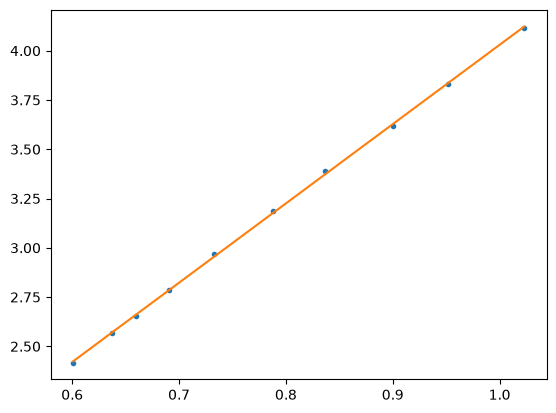

In [23]:

plt.figure()
plt.plot(l_gemeten,T_squared,'.')
plt.plot(l_gemeten, T_fit(l_gemeten,a_fit,b_fit))
plt.show()

**Observations:**  
**Notes:**  

## Processing
**Description of processing of raw data into scientific evidence:**


In [ ]:
#Data processing and analysis:


In [ ]:
#Data processing and analysis:


In [ ]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [ ]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

## Discussion



## Conclusion

## Additional notes, remarks, explanations, thoughts etc